# Bengali Troll Meme Analysis — P0 Plain Prompting with Pixtral-12B

Bengali Multimodal Troll Meme Analysis
Setting P0 : Plain prompting (NO gold labels in the prompt)
Model      : Mistral/Pixtral-12B  (natively multimodal Pixtral, ~9B LM / ~10B total)
Platform   : Kaggle Notebook, GPU T4 x2 (fp16, sharded) or 1 x T4 (4-bit)

The model receives only the meme image and is asked to produce:
(1) an explanation,
(2) the target category        -> {individual, organization, community, concept}
(3) the primary troll mechanism -> {direct_derision, comparative_stereotypical_ridicule,
ironic_deceptive_framing, provocative_baiting}
A robust parser converts the raw generation into labels, and the evaluation block
computes Acc, P/R/F1 (macro, weighted, micro), class-wise P/R/F1, kappa, MCC,
and prints/saves confusion matrices for each classification task.

Every "# %%" marker below is one Kaggle notebook cell.

## [Cell 1] Install dependencies (Kaggle: Settings -> Internet ON, Accelerator -> GPU T4 x2)

In [1]:
# Qwen3.5 needs transformers >= 5.2. Restart the kernel once after this cell if Kaggle
# had an older transformers already imported.
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U",
                "transformers>=5.2", "accelerate>=1.1.0", "bitsandbytes",
                "scikit-learn", "seaborn"], check=False)
# Optional speed-up kernels for Qwen3.5's linear-attention layers (safe to skip;
# transformers falls back to a pure-PyTorch implementation):
# subprocess.run([sys.executable, "-m", "pip", "install", "-q",
#                 "flash-linear-attention", "causal-conv1d"], check=False)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 76.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 36.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 54.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 516.0/516.0 kB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 60.1 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sklearn-compat 0.1.5 requires scikit-learn<1.9,>=1.2, but you have scikit-learn 1.9.1 which is incompatible.


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '-U', 'transformers>=5.2', 'accelerate>=1.1.0', 'bitsandbytes', 'scikit-learn', 'seaborn'], returncode=0)

## [Cell 2] Configuration  <-- EDIT THIS CELL ONLY

In [2]:
import os

CFG = {
    # ---------------- model ----------------
    "MODEL_ID": "Qwen/Qwen3.5-9B",
    # "fp16" -> full fp16 weights sharded over 2 x T4 (recommended, ~20 GB)
    # "4bit" -> NF4 quantisation, fits a single T4 / P100 (~7 GB)
    # "bf16" -> use only if fp16 gives NaN/"!!!!" outputs (slow on T4: emulated)
    # "fp32" -> CPU debugging only
    "LOAD_MODE": "fp16",

    # ---------------- data ----------------
    # Either the JSON exported by the Chihna annotator, or a CSV file.
    "DATA_FILE": "/kaggle/input/datasets/mranikmahmudshanto/trollmeme-bn/troll_only_text.json",
    "IMAGE_ROOT": "/kaggle/input/datasets/mranikmahmudshanto/trollmeme-bn/labeled_images/labeled_images",
    # Column names used ONLY when DATA_FILE is a CSV
    "CSV_COLS": {
        "id": "image",               # image filename or relative path
        "target": "target_category",
        "mechanism": "trolling_mechanism",
        "explanation": "explanation",
        "troll": "troll_label",      # optional; rows != troll are dropped if present
    },

    # ---------------- generation ----------------
    "EXPLANATION_LANGUAGE": "English",   # language of the generated explanation
    "MAX_IMAGE_SIDE": 1024,              # longest image side in pixels (memory control)
    "MAX_NEW_TOKENS": 512,
    "DO_SAMPLE": False,                  # greedy decoding for reproducibility
    "REPETITION_PENALTY": 1.05,
    "SEED": 42,
    "LIMIT": None,                       # e.g. 20 for a quick smoke test, None = all

    # ---------------- output ----------------
    "RUN_NAME": "qwen35_9b_P0_plain",
    "OUT_DIR": "/kaggle/working/results",
}
if not os.path.exists("/kaggle"):          # local runs
    CFG["OUT_DIR"] = "./results"
RUN_DIR = os.path.join(CFG["OUT_DIR"], CFG["RUN_NAME"])
os.makedirs(RUN_DIR, exist_ok=True)
PRED_FILE = os.path.join(RUN_DIR, "predictions.jsonl")
print("Outputs ->", RUN_DIR)

Outputs -> /kaggle/working/results/qwen35_9b_P0_plain


In [3]:
# --- CFG (only diffs from Qwen run) ---
CFG.update({
    "MODEL_ID": "mistral-community/pixtral-12b",
    "LOAD_MODE": "4bit",          # 12B fp16 (~24GB) won't fit a single T4/P100; 4bit ~9GB
    "RUN_NAME": "pixtral_12b_P0_plain",
})
RUN_DIR = os.path.join(CFG["OUT_DIR"], CFG["RUN_NAME"])
os.makedirs(RUN_DIR, exist_ok=True)
PRED_FILE = os.path.join(RUN_DIR, "predictions.jsonl")
print("Outputs ->", RUN_DIR)

Outputs -> /kaggle/working/results/pixtral_12b_P0_plain


## [Cell 3] Label space and definitions (shared by prompt, parser and evaluation)

In [4]:
TARGET_LABELS = ["individual", "organization", "community", "concept"]
MECH_LABELS = ["direct_derision", "comparative_stereotypical_ridicule",
               "ironic_deceptive_framing", "provocative_baiting"]
INVALID = "INVALID"          # used when the output cannot be mapped to a valid label

TARGET_DEFS = {
    "individual":   "a specific, identifiable person (e.g., a politician, celebrity, player, influencer).",
    "organization": "a formal institution or structured group (e.g., political party, government body, "
                    "company, university, team/club, media outlet, agency).",
    "community":    "people sharing an identity or affiliation (e.g., religion, gender, region, "
                    "nationality, profession, class, ideology, fandom).",
    "concept":      "a belief, behaviour, event, policy, practice, trend, or other abstract entity.",
}
MECH_DEFS = {
    "direct_derision": "explicit insult, humiliation, dismissal, or mockery of the target.",
    "comparative_stereotypical_ridicule": "degrading comparison, analogy, contrast, or stereotype.",
    "ironic_deceptive_framing": "sarcasm, ironic praise, parody, misleading framing, or "
                                "text-image contradiction.",
    "provocative_baiting": "inflammatory content intended to trigger conflict or outrage.",
}
TASKS = {
    "target":    {"labels": TARGET_LABELS, "gold": "gold_target",    "pred": "pred_target",
                  "title": "Target Identification"},
    "mechanism": {"labels": MECH_LABELS,   "gold": "gold_mechanism", "pred": "pred_mechanism",
                  "title": "Trolling Mechanism"},
}

## [Cell 4] Plain prompt (P0) - no gold target, no gold mechanism, no gold explanation

In [5]:
def build_prompt_p0(lang: str = "English") -> str:
    t_defs = "\n".join(f"- {k}: {v}" for k, v in TARGET_DEFS.items())
    m_defs = "\n".join(f"- {k}: {v}" for k, v in MECH_DEFS.items())
    return f"""You are an expert analyst of Bengali social-media troll memes.
The given image is a Bengali troll meme. Read its Bengali text and inspect its visual content carefully, then complete the three tasks below.

Task 1 - Explanation: write a concise, self-contained explanation in {lang} (3-5 sentences). Describe the relevant Bengali text and visual cues, the implied meaning, who or what is targeted, and how the meme ridicules, humiliates, deceptively frames, stereotypes, or provokes the target. Do not invent background facts that are not supported by the meme.

Task 2 - Target category: choose exactly ONE of the following labels.
{t_defs}

Task 3 - Primary trolling mechanism: choose exactly ONE of the following labels.
{m_defs}

Return ONLY one valid JSON object, with no markdown and no text before or after it, in exactly this format:
{{"explanation": "<your explanation>", "target_category": "<one of: {' | '.join(TARGET_LABELS)}>", "trolling_mechanism": "<one of: {' | '.join(MECH_LABELS)}>"}}"""

PROMPT_P0 = build_prompt_p0(CFG["EXPLANATION_LANGUAGE"])
print(PROMPT_P0)

You are an expert analyst of Bengali social-media troll memes.
The given image is a Bengali troll meme. Read its Bengali text and inspect its visual content carefully, then complete the three tasks below.

Task 1 - Explanation: write a concise, self-contained explanation in English (3-5 sentences). Describe the relevant Bengali text and visual cues, the implied meaning, who or what is targeted, and how the meme ridicules, humiliates, deceptively frames, stereotypes, or provokes the target. Do not invent background facts that are not supported by the meme.

Task 2 - Target category: choose exactly ONE of the following labels.
- individual: a specific, identifiable person (e.g., a politician, celebrity, player, influencer).
- organization: a formal institution or structured group (e.g., political party, government body, company, university, team/club, media outlet, agency).
- community: people sharing an identity or affiliation (e.g., religion, gender, region, nationality, profession, cl

## [Cell 5] Output parser (robust to <think> blocks, code fences, broken JSON, synonyms)

In [6]:
import re, json, ast, difflib

TARGET_ALIASES = {
    "individual": ["individual", "person", "individual person", "specific person", "politician",
                   "celebrity", "public figure", "player", "influencer", "ind"],
    "organization": ["organization", "organisation", "institution", "political party", "party",
                     "company", "government", "university", "team", "club", "media", "agency", "org"],
    "community": ["community", "group", "social group", "religious group", "gender group", "fandom",
                  "fan group", "profession", "nationality", "regional group", "people", "com"],
    "concept": ["concept", "idea", "belief", "behaviour", "behavior", "event", "policy", "practice",
                "trend", "abstract", "abstract entity", "con"],
}
MECH_ALIASES = {
    "direct_derision": ["direct_derision", "direct derision", "derision", "direct", "insult",
                        "humiliation", "mockery", "ridicule", "drd"],
    "comparative_stereotypical_ridicule": ["comparative_stereotypical_ridicule",
                        "comparative/stereotypical ridicule", "comparative stereotypical ridicule",
                        "comparative ridicule", "stereotypical ridicule", "comparative",
                        "stereotypical", "stereotype", "comparison", "analogy", "csr"],
    "ironic_deceptive_framing": ["ironic_deceptive_framing", "ironic/deceptive framing",
                        "ironic deceptive framing", "ironic framing", "deceptive framing", "ironic",
                        "irony", "sarcasm", "sarcastic", "parody", "deceptive", "idf"],
    "provocative_baiting": ["provocative_baiting", "provocative baiting", "provocative", "baiting",
                        "bait", "provocation", "inflammatory", "rage bait", "pbt"],
}
ALIASES = {"target": TARGET_ALIASES, "mechanism": MECH_ALIASES}
KEYS = {  # accepted JSON keys per field
    "explanation": ["explanation", "explanation_text", "reasoning", "rationale"],
    "target": ["target_category", "target", "target_type", "target_identification"],
    "mechanism": ["trolling_mechanism", "mechanism", "primary_mechanism", "troll_mechanism"],
}


def _canon(s) -> str:
    s = str(s).strip().lower()
    s = re.sub(r"[\"'`*.,;:()\[\]{}]", " ", s)
    s = re.sub(r"[\s/\-]+", " ", s).strip()
    return s


def normalize_label(raw, task: str) -> str:
    """Map a raw string to a canonical label of `task` ('target' | 'mechanism') or INVALID."""
    if raw is None:
        return INVALID
    labels = TASKS[task]["labels"]
    s = _canon(raw)
    if not s or s in {"na", "n a", "none", "null", "unknown"}:
        return INVALID
    s_us = s.replace(" ", "_")
    if s_us in labels:
        return s_us
    alias_map = {_canon(a): lab for lab, al in ALIASES[task].items() for a in al}
    if s in alias_map:
        return alias_map[s]
    # the longest alias contained in the string (e.g. "political party (organization)")
    hits = sorted(((a, lab) for a, lab in alias_map.items()
                   if len(a) > 3 and re.search(rf"\b{re.escape(a)}\b", s)),
                  key=lambda x: -len(x[0]))
    if hits:
        best_len = len(hits[0][0])
        if len({lab for a, lab in hits if len(a) == best_len}) == 1:
            return hits[0][1]
    close = difflib.get_close_matches(s, list(alias_map), n=1, cutoff=0.80)
    return alias_map[close[0]] if close else INVALID


def strip_thinking(text: str) -> str:
    text = re.sub(r"<think>.*?</think>", "", text, flags=re.S | re.I)
    if "</think>" in text:                      # opening tag lost in decoding
        text = text.split("</think>")[-1]
    return text.strip()


def _json_candidates(text: str):
    for m in re.finditer(r"```(?:json)?\s*(.*?)```", text, flags=re.S | re.I):
        yield m.group(1)
    depth, start = 0, None                      # balanced-brace scan
    for i, ch in enumerate(text):
        if ch == "{":
            if depth == 0:
                start = i
            depth += 1
        elif ch == "}" and depth:
            depth -= 1
            if depth == 0 and start is not None:
                yield text[start:i + 1]
    if "{" in text and text.count("{") > text.count("}"):   # truncated object
        yield text[text.index("{"):] + '"}'


def _try_load(s: str):
    s = s.strip().replace("\u201c", '"').replace("\u201d", '"').replace("\u2019", "'")
    s2 = re.sub(r",\s*([}\]])", r"\1", s)       # trailing commas
    for cand in (s, s2):
        try:
            obj = json.loads(cand)
            if isinstance(obj, dict):
                return obj
        except Exception:
            pass
        try:
            obj = ast.literal_eval(cand)
            if isinstance(obj, dict):
                return obj
        except Exception:
            pass
    return None


def _get_key(d: dict, field: str):
    low = {str(k).strip().lower(): v for k, v in d.items()}
    for k in KEYS[field]:
        if k in low:
            return low[k]
    return None


def _regex_field(text: str, field: str):
    keys = "|".join(re.escape(k) for k in KEYS[field])
    if field == "explanation":
        m = re.search(rf'"?(?:{keys})"?\s*[:=]\s*"(.*?)"\s*(?:,\s*"|\}}|$)', text, flags=re.S | re.I)
        if not m:   # unquoted "Explanation: ..." style, up to the next field line
            m = re.search(rf'\**(?:{keys})\**\s*[:=]\s*(.+?)(?=\n\s*\**\s*(?:target|trolling|mechanism|primary)|\Z)',
                          text, flags=re.S | re.I)
    else:
        m = re.search(rf'"?(?:{keys})"?\s*[:=\-]\s*"?([A-Za-z_ /\-]+)', text, flags=re.I)
    return m.group(1).strip() if m else None


def _single_label_mention(text: str, task: str):
    """Last resort: accept a label only if exactly one canonical label is mentioned."""
    found = {lab for lab in TASKS[task]["labels"]
             if re.search(rf"\b{re.escape(lab)}\b|\b{re.escape(lab.replace('_', ' '))}\b", text, re.I)}
    return found.pop() if len(found) == 1 else None


def parse_output(raw: str) -> dict:
    text = strip_thinking(raw or "")
    obj, status = None, "failed"
    for cand in _json_candidates(text):
        obj = _try_load(cand)
        if obj is not None and (_get_key(obj, "target") is not None
                                or _get_key(obj, "mechanism") is not None):
            status = "json"
            break
        obj = None
    out = {}
    for field in ("explanation", "target", "mechanism"):
        val = _get_key(obj, field) if obj else None
        if val is None:
            val = _regex_field(text, field)
            if val is not None and status == "failed":
                status = "regex"
        out[field] = val
    for task in ("target", "mechanism"):
        lab = normalize_label(out[task], task)
        if lab == INVALID:
            fb = _single_label_mention(text, task)
            if fb:
                lab, status = fb, (status if status != "failed" else "mention")
        out[task] = lab
    if not out["explanation"]:
        out["explanation"] = text if status == "failed" else ""
    return {"pred_explanation": str(out["explanation"]).strip(),
            "pred_target": out["target"], "pred_mechanism": out["mechanism"],
            "parse_status": status}


# quick self-test of the parser
_tests = [
    '{"explanation": "x", "target_category": "Organization", "trolling_mechanism": "Ironic / Deceptive Framing"}',
    '<think>hmm</think>```json\n{"explanation":"y","target_category":"political party","trolling_mechanism":"sarcasm",}\n```',
    'Target: community\nMechanism: CSR',
    '{"explanation": "cut off',
]
for t in _tests:
    print(parse_output(t))

{'pred_explanation': 'x', 'pred_target': 'organization', 'pred_mechanism': 'ironic_deceptive_framing', 'parse_status': 'json'}
{'pred_explanation': 'y', 'pred_target': 'organization', 'pred_mechanism': 'ironic_deceptive_framing', 'parse_status': 'json'}
{'pred_explanation': '', 'pred_target': 'community', 'pred_mechanism': 'comparative_stereotypical_ridicule', 'parse_status': 'regex'}
{'pred_explanation': '{"explanation": "cut off', 'pred_target': 'INVALID', 'pred_mechanism': 'INVALID', 'parse_status': 'failed'}


## [Cell 6] Load dataset (Chihna JSON export or CSV) and resolve image paths

In [7]:
import pandas as pd


def _index_images(root: str) -> dict:
    idx = {}
    exts = (".jpg", ".jpeg", ".png", ".webp", ".bmp", ".gif")
    for dp, _, fns in os.walk(root):
        for fn in fns:
            if fn.lower().endswith(exts):
                idx.setdefault(fn, os.path.join(dp, fn))
                idx.setdefault(os.path.splitext(fn)[0], os.path.join(dp, fn))
    return idx


def _field(value, *keys):
    """Return value[key] if value is a dict, the value itself if it is a string/number, else None."""
    if value is None:
        return None
    if isinstance(value, dict):
        for k in keys:
            if value.get(k) not in (None, ""):
                return value[k]
        return None
    return value


def _first(a: dict, *names):
    """Return the first non-empty top-level field among several possible key names."""
    for n in names:
        if a.get(n) not in (None, "", {}):
            return a[n]
    return None


def load_dataset(cfg) -> pd.DataFrame:
    path = cfg["DATA_FILE"]
    rows = []
    if path.lower().endswith(".json"):
        with open(path, encoding="utf-8") as f:
            data = json.load(f)
        anns = data.get("annotations", data) if isinstance(data, dict) else data
        if isinstance(anns, dict):                      # {"img1.jpg": {...}, ...} layout
            anns = [{**v, "image": v.get("image", k)} for k, v in anns.items()]

        for a in anns:
            if not isinstance(a, dict):
                continue
            if a.get("status") not in (None, "annotated"):
                continue

            # troll label (dict {"label": ...} or plain string)
            troll = _field(_first(a, "troll_detection", "troll_label", "troll"), "label")
            if troll is not None and str(troll).strip().lower().replace("-", "_") not in ("troll", "1"):
                continue

            # image (dict {"filename", "relative_path"} or plain string path)
            img = _first(a, "image", "filename", "image_path", "file")
            if isinstance(img, dict):
                rel = img.get("relative_path") or img.get("filename") or img.get("path")
                fname = img.get("filename") or (os.path.basename(rel) if rel else None)
            else:
                rel = str(img) if img is not None else None
                fname = os.path.basename(rel) if rel else None

            rows.append({
                "id": rel,
                "filename": fname,
                "gold_target": _field(_first(a, "target_identification", "target_category", "target"),
                                      "category", "label"),
                "gold_mechanism": _field(_first(a, "trolling_mechanism", "mechanism", "troll_mechanism"),
                                         "primary", "label"),
                "gold_explanation": _field(_first(a, "explanation", "gold_explanation", "final_explanation"),
                                           "text", "final_text") or "",
            })
        df = pd.DataFrame(rows, columns=["id", "filename", "gold_target", "gold_mechanism", "gold_explanation"])
    else:
        c = cfg["CSV_COLS"]
        raw = pd.read_csv(path)
        if c.get("troll") in raw.columns:
            raw = raw[raw[c["troll"]].astype(str).str.lower().str.replace("-", "_").isin(["troll", "1"])]
        df = pd.DataFrame({
            "id": raw[c["id"]].astype(str),
            "filename": raw[c["id"]].astype(str).map(os.path.basename),
            "gold_target": raw[c["target"]],
            "gold_mechanism": raw[c["mechanism"]],
            "gold_explanation": raw[c["explanation"]] if c["explanation"] in raw.columns else "",
        })

    if df.empty:
        raise ValueError("No records loaded. Print one record with: "
                         "print(json.dumps(anns[0], indent=2, ensure_ascii=False)[:1500])")

    # normalise gold labels with the same mapper as predictions
    df["gold_target"] = df["gold_target"].map(lambda x: normalize_label(x, "target"))
    df["gold_mechanism"] = df["gold_mechanism"].map(lambda x: normalize_label(x, "mechanism"))
    bad = df[(df.gold_target == INVALID) | (df.gold_mechanism == INVALID)]
    if len(bad):
        print(f"[warn] dropping {len(bad)} rows with missing/unknown gold labels")
        df = df.drop(bad.index)

    # resolve images
    idx = _index_images(cfg["IMAGE_ROOT"])

    def _resolve(r):
        p = os.path.join(cfg["IMAGE_ROOT"], str(r["id"]))
        if os.path.isfile(p):
            return p
        return idx.get(str(r["filename"])) or idx.get(os.path.splitext(str(r["filename"]))[0])

    df["image_path"] = df.apply(_resolve, axis=1)
    miss = df.image_path.isna().sum()
    if miss:
        print(f"[warn] {miss} images not found and skipped")
        df = df[df.image_path.notna()]
    df = df.drop_duplicates("id").reset_index(drop=True)
    if cfg["LIMIT"]:
        df = df.head(cfg["LIMIT"])
    return df


df = load_dataset(CFG)
print(f"Loaded {len(df)} troll memes")
print(df.gold_target.value_counts(), "\n")
print(df.gold_mechanism.value_counts())

Loaded 1200 troll memes
gold_target
individual      679
concept         256
community       240
organization     25
Name: count, dtype: int64 

gold_mechanism
direct_derision                       587
ironic_deceptive_framing              265
comparative_stereotypical_ridicule    235
provocative_baiting                   113
Name: count, dtype: int64


## [Cell 7] Load Qwen3.5-9B

In [8]:
import torch, random, numpy as np
from transformers import AutoProcessor, AutoModelForImageTextToText, BitsAndBytesConfig

random.seed(CFG["SEED"]); np.random.seed(CFG["SEED"]); torch.manual_seed(CFG["SEED"])
n_gpu = torch.cuda.device_count()
print("GPUs:", [torch.cuda.get_device_name(i) for i in range(n_gpu)])

# --- model loading (diff: skip_modules names differ from Qwen's "visual") ---
processor = AutoProcessor.from_pretrained(CFG["MODEL_ID"])
load_kw = {"device_map": "auto", "attn_implementation": "sdpa"}
if CFG["LOAD_MODE"] == "4bit":
    load_kw["quantization_config"] = BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=torch.float16,
        llm_int8_skip_modules=["vision_tower", "multi_modal_projector", "lm_head"],
    )
    load_kw["dtype"] = torch.float16
else:
    load_kw["dtype"] = {"bf16": torch.bfloat16, "fp32": torch.float32}.get(CFG["LOAD_MODE"], torch.float16)
    if n_gpu >= 2:
        load_kw["max_memory"] = {0: "11GiB", **{i: "14GiB" for i in range(1, n_gpu)}}

model = AutoModelForImageTextToText.from_pretrained(CFG["MODEL_ID"], **load_kw).eval()
print("Params: %.2fB" % (sum(p.numel() for p in model.parameters()) / 1e9))
print(getattr(model, "hf_device_map", None) and set(model.hf_device_map.values()))

GPUs: ['Tesla T4', 'Tesla T4']


processor_config.json:   0%|          | 0.00/162 [00:00<?, ?B/s]

chat_template.json: 0.00B [00:00, ?B/s]

preprocessor_config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

...

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/585 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

Params: 7.01B
{0, 1}


## [Cell 8] Inference helpers

In [9]:
import time
from PIL import Image


def load_image(path: str, max_side: int) -> Image.Image:
    img = Image.open(path)
    if img.mode in ("RGBA", "LA", "P"):
        img = img.convert("RGBA")
        bg = Image.new("RGB", img.size, (255, 255, 255))
        bg.paste(img, mask=img.split()[-1])
        img = bg
    img = img.convert("RGB")
    w, h = img.size
    if max(w, h) > max_side:
        s = max_side / max(w, h)
        img = img.resize((max(28, int(w * s)), max(28, int(h * s))), Image.BICUBIC)
    return img


# --- generate() diff: drop enable_thinking (Qwen-only kwarg) ---
@torch.inference_mode()
def generate(image: Image.Image, prompt: str) -> str:
    messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": prompt}]}]
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = processor(text=[text], images=[image], return_tensors="pt").to(model.device)
    gen_kw = dict(max_new_tokens=CFG["MAX_NEW_TOKENS"], do_sample=CFG["DO_SAMPLE"],
                  repetition_penalty=CFG["REPETITION_PENALTY"])
    if CFG["DO_SAMPLE"]:
        gen_kw.update(temperature=0.7, top_p=0.8, top_k=20)
    else:
        gen_kw.update(temperature=None, top_p=None, top_k=None)
    out = model.generate(**inputs, **gen_kw)
    new_tokens = out[0, inputs["input_ids"].shape[1]:]
    return processor.decode(new_tokens, skip_special_tokens=True).strip()


def safe_generate(path: str, prompt: str) -> str:
    """Retry with smaller images on CUDA OOM."""
    for side in (CFG["MAX_IMAGE_SIDE"], 768, 512):
        try:
            return generate(load_image(path, side), prompt)
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            print(f"  OOM at {side}px, retrying smaller")
    raise RuntimeError("OOM even at 512px")


# sanity check: fp16 overflow on T4 shows up as '!!!!!' or empty output
_raw = safe_generate(df.image_path.iloc[0], PROMPT_P0)
print(_raw, "\n->", parse_output(_raw))
if re.fullmatch(r"[!\s]*", _raw):
    raise RuntimeError("Degenerate output (NaN in fp16). Set LOAD_MODE='4bit' or 'bf16' and reload.")

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


```json
{
  "explanation": "The meme features a character with exaggerated facial features and a green outfit, repeated twice. The accompanying Bengali text humorously describes a scenario where someone is trying to explain something complex but ends up confusing others, implying ineffectiveness or lack of clarity. The repetition of the character emphasizes the confusion.",
  "target_category": "concept",
  "trolling_mechanism": "comparative_stereotypical_ridicule"
}
``` 
-> {'pred_explanation': 'The meme features a character with exaggerated facial features and a green outfit, repeated twice. The accompanying Bengali text humorously describes a scenario where someone is trying to explain something complex but ends up confusing others, implying ineffectiveness or lack of clarity. The repetition of the character emphasizes the confusion.', 'pred_target': 'concept', 'pred_mechanism': 'comparative_stereotypical_ridicule', 'parse_status': 'json'}


## [Cell 9] Run P0 over the dataset (resumable: re-running skips finished items)

In [10]:
from tqdm.auto import tqdm

done = set()
if os.path.exists(PRED_FILE):
    with open(PRED_FILE, encoding="utf-8") as f:
        done = {json.loads(l)["id"] for l in f if l.strip()}
print(f"{len(done)} already done, {len(df) - len(done)} remaining")

with open(PRED_FILE, "a", encoding="utf-8") as fout:
    for _, r in tqdm(df.iterrows(), total=len(df)):
        if r["id"] in done:
            continue
        t0 = time.time()
        try:
            raw, err = safe_generate(r["image_path"], PROMPT_P0), None
        except Exception as e:                      # keep going; counts as INVALID
            raw, err = "", repr(e)
        rec = {"id": r["id"], "image_path": r["image_path"],
               "gold_target": r["gold_target"], "gold_mechanism": r["gold_mechanism"],
               "gold_explanation": r["gold_explanation"],
               "raw_output": raw, "error": err, "latency_s": round(time.time() - t0, 2),
               **parse_output(raw)}
        fout.write(json.dumps(rec, ensure_ascii=False) + "\n")
        fout.flush()

0 already done, 1200 remaining


  0%|          | 0/1200 [00:00<?, ?it/s]

## [Cell 10] Evaluation: overall + class-wise metrics + confusion matrices

Evaluating 1200 predictions
Parse status:
 parse_status
json      1184
regex       11
failed       5 


Target Identification  (n=1200, invalid=9, 0.8%)
Accuracy      : 0.4708      Balanced Acc: 0.4300
Macro    P/R/F1: 0.4319 / 0.4300 / 0.4225
Weighted P/R/F1: 0.5267 / 0.4708 / 0.4876
Micro    P/R/F1: 0.4744 / 0.4708 / 0.4726
Cohen kappa   : 0.1824      MCC: 0.1876

Class-wise metrics:
       class  precision  recall     f1  support  predicted
  individual     0.6838  0.5096 0.5840      679        506
organization     0.4091  0.3600 0.3830       25         22
   community     0.3117  0.4792 0.3777      240        369
     concept     0.3231  0.3711 0.3455      256        294
   macro avg     0.4319  0.4300 0.4225     1200       1191
weighted avg     0.5267  0.4708 0.4876     1200       1191

Confusion matrix (rows = gold, columns = predicted):
                   pred:individual  pred:organization  pred:community  pred:concept  pred:INVALID
gold:individual                346            

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


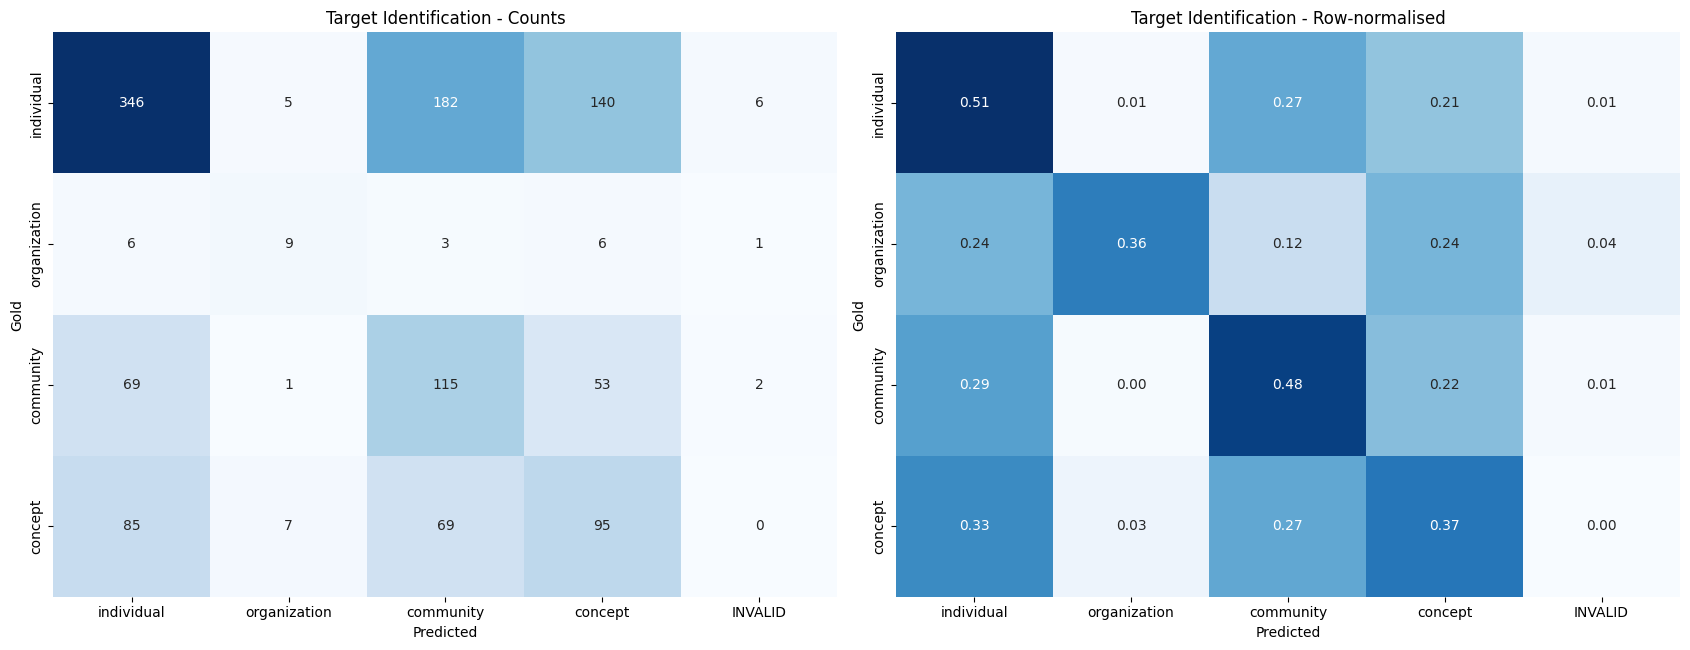

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")



Trolling Mechanism  (n=1200, invalid=6, 0.5%)
Accuracy      : 0.3225      Balanced Acc: 0.3294
Macro    P/R/F1: 0.3522 / 0.3294 / 0.2724
Weighted P/R/F1: 0.4276 / 0.3225 / 0.3038
Micro    P/R/F1: 0.3241 / 0.3225 / 0.3233
Cohen kappa   : 0.0932      MCC: 0.1157

Class-wise metrics:
                             class  precision  recall     f1  support  predicted
                   direct_derision     0.5781  0.2334 0.3325      587        237
comparative_stereotypical_ridicule     0.2474  0.7957 0.3774      235        756
          ironic_deceptive_framing     0.3272  0.2000 0.2482      265        162
               provocative_baiting     0.2564  0.0885 0.1316      113         39
                         macro avg     0.3522  0.3294 0.2724     1200       1194
                      weighted avg     0.4276  0.3225 0.3038     1200       1194

Confusion matrix (rows = gold, columns = predicted):
                                         pred:direct_derision  pred:comparative_stereotypical_ri

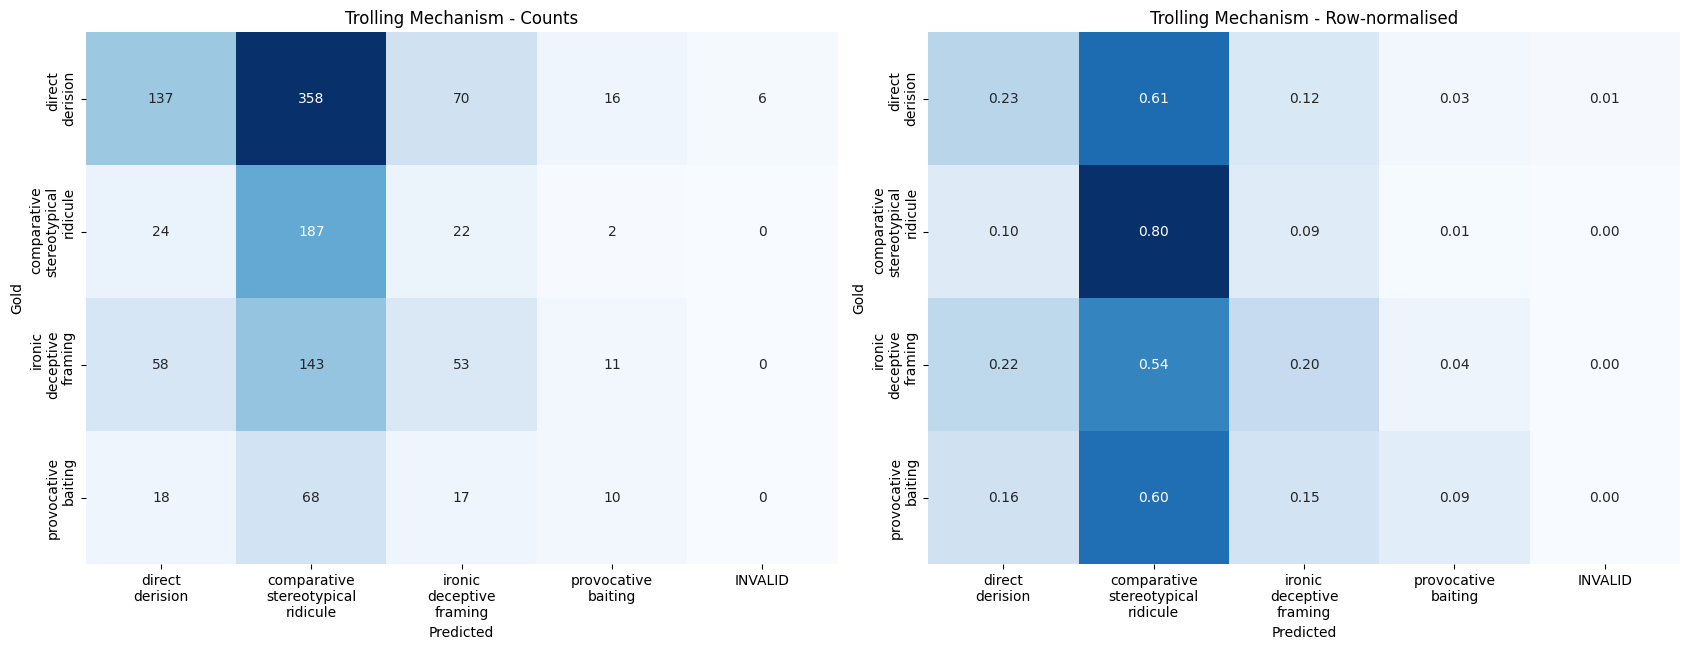


Joint accuracy (target AND mechanism correct): 0.1842

--- Parsed-only (INVALID removed) accuracy / macro-F1 ---
Target Identification    n=1191  acc=0.4744  macro-F1=0.4257
Trolling Mechanism       n=1194  acc=0.3241  macro-F1=0.2730


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix,
                             cohen_kappa_score, matthews_corrcoef, balanced_accuracy_score)

pred = pd.read_json(PRED_FILE, lines=True)
pred = pred[pred.id.isin(df.id)].drop_duplicates("id", keep="last").reset_index(drop=True)
# re-parse from raw output so parser fixes apply without re-running the model
pred[["pred_explanation", "pred_target", "pred_mechanism", "parse_status"]] = \
    pred.raw_output.fillna("").map(parse_output).apply(pd.Series)
print(f"Evaluating {len(pred)} predictions")
print("Parse status:\n", pred.parse_status.value_counts().to_string(), "\n")


def evaluate_task(y_true, y_pred, labels, title, tag):
    y_true, y_pred = list(y_true), list(y_pred)
    n = len(y_true)
    n_inv = sum(p == INVALID for p in y_pred)
    res = {"task": title, "n": n, "invalid": n_inv, "invalid_rate": n_inv / n,
           # INVALID predictions are counted as errors (strict evaluation)
           "accuracy": accuracy_score(y_true, y_pred),
           "balanced_acc": balanced_accuracy_score(y_true, y_pred),
           "cohen_kappa": cohen_kappa_score(y_true, y_pred),
           "mcc": matthews_corrcoef(y_true, y_pred)}
    for avg in ("macro", "weighted", "micro"):
        p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels,
                                                     average=avg, zero_division=0)
        res.update({f"{avg}_precision": p, f"{avg}_recall": r, f"{avg}_f1": f})

    # class-wise
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=labels,
                                                 average=None, zero_division=0)
    cw = pd.DataFrame({"class": labels, "precision": p, "recall": r, "f1": f, "support": s,
                       "predicted": [y_pred.count(l) for l in labels]})
    cw.loc[len(cw)] = ["macro avg", res["macro_precision"], res["macro_recall"],
                       res["macro_f1"], n, n - n_inv]
    cw.loc[len(cw)] = ["weighted avg", res["weighted_precision"], res["weighted_recall"],
                       res["weighted_f1"], n, n - n_inv]

    # confusion matrix (rows = gold, cols = predicted; INVALID column if needed)
    cols = labels + ([INVALID] if n_inv else [])
    cm = confusion_matrix(y_true, y_pred, labels=cols)[:len(labels)]
    cm_df = pd.DataFrame(cm, index=[f"gold:{l}" for l in labels], columns=[f"pred:{c}" for c in cols])

    # print
    bar = "=" * 78
    print(f"\n{bar}\n{title}  (n={n}, invalid={n_inv}, {100*n_inv/n:.1f}%)\n{bar}")
    print(f"Accuracy      : {res['accuracy']:.4f}      Balanced Acc: {res['balanced_acc']:.4f}")
    print(f"Macro    P/R/F1: {res['macro_precision']:.4f} / {res['macro_recall']:.4f} / {res['macro_f1']:.4f}")
    print(f"Weighted P/R/F1: {res['weighted_precision']:.4f} / {res['weighted_recall']:.4f} / {res['weighted_f1']:.4f}")
    print(f"Micro    P/R/F1: {res['micro_precision']:.4f} / {res['micro_recall']:.4f} / {res['micro_f1']:.4f}")
    print(f"Cohen kappa   : {res['cohen_kappa']:.4f}      MCC: {res['mcc']:.4f}")
    print("\nClass-wise metrics:")
    print(cw.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    print("\nConfusion matrix (rows = gold, columns = predicted):")
    print(cm_df.to_string())

    # save
    cw.to_csv(os.path.join(RUN_DIR, f"classwise_{tag}.csv"), index=False)
    cm_df.to_csv(os.path.join(RUN_DIR, f"confusion_{tag}.csv"))
    fig, axes = plt.subplots(1, 2, figsize=(6 + 2.2 * len(cols), 0.9 * len(labels) + 3))
    short = [c.replace("_", "\n") for c in cols]
    row_norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    for ax, mat, fmt, name in ((axes[0], cm, "d", "Counts"), (axes[1], row_norm, ".2f", "Row-normalised")):
        sns.heatmap(mat, annot=True, fmt=fmt, cmap="Blues", cbar=False, ax=ax,
                    xticklabels=short, yticklabels=[l.replace("_", "\n") for l in labels])
        ax.set_xlabel("Predicted"); ax.set_ylabel("Gold"); ax.set_title(f"{title} - {name}")
    plt.tight_layout()
    plt.savefig(os.path.join(RUN_DIR, f"confusion_{tag}.png"), dpi=300, bbox_inches="tight")
    plt.show()
    return res, cw, cm_df


results = {}
for tag, t in TASKS.items():
    results[tag] = evaluate_task(pred[t["gold"]], pred[t["pred"]], t["labels"], t["title"], tag)

# joint correctness (both labels right)
joint = ((pred.gold_target == pred.pred_target) & (pred.gold_mechanism == pred.pred_mechanism)).mean()
print(f"\nJoint accuracy (target AND mechanism correct): {joint:.4f}")

# Secondary view: metrics on successfully parsed outputs only (report alongside strict numbers)
print("\n--- Parsed-only (INVALID removed) accuracy / macro-F1 ---")
for tag, t in TASKS.items():
    m = pred[t["pred"]] != INVALID
    if m.any():
        _, _, f, _ = precision_recall_fscore_support(pred.loc[m, t["gold"]], pred.loc[m, t["pred"]],
                                                     labels=t["labels"], average="macro", zero_division=0)
        print(f"{t['title']:<24} n={m.sum():<5} acc={accuracy_score(pred.loc[m, t['gold']], pred.loc[m, t['pred']]):.4f}  macro-F1={f:.4f}")

## [Cell 11] Summary table (CSV + LaTeX) and saved artefacts

In [12]:
summary = pd.DataFrame([r[0] for r in results.values()]).set_index("task")
summary["joint_accuracy"] = joint
summary.insert(0, "model", CFG["MODEL_ID"]); summary.insert(1, "setting", "P0-plain")
print(summary.T.to_string(float_format=lambda x: f"{x:.4f}"))
summary.to_csv(os.path.join(RUN_DIR, "summary_metrics.csv"))
with open(os.path.join(RUN_DIR, "summary_metrics.tex"), "w") as f:
    f.write(summary[["accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1",
                     "cohen_kappa", "mcc", "invalid_rate"]]
            .to_latex(float_format="%.4f", caption=f"{CFG['MODEL_ID']} P0 plain prompting",
                      label="tab:p0_qwen35"))
pred.to_csv(os.path.join(RUN_DIR, "predictions_parsed.csv"), index=False)   # for explanation eval
with open(os.path.join(RUN_DIR, "run_config.json"), "w") as f:
    json.dump({**CFG, "prompt": PROMPT_P0}, f, indent=2, ensure_ascii=False)
print("\nSaved to", RUN_DIR, ":", sorted(os.listdir(RUN_DIR)))

task                        Target Identification             Trolling Mechanism
model               mistral-community/pixtral-12b  mistral-community/pixtral-12b
setting                                  P0-plain                       P0-plain
n                                            1200                           1200
invalid                                         9                              6
invalid_rate                               0.0075                         0.0050
accuracy                                   0.4708                         0.3225
balanced_acc                               0.4300                         0.3294
cohen_kappa                                0.1824                         0.0932
mcc                                        0.1876                         0.1157
macro_precision                            0.4319                         0.3522
macro_recall                               0.4300                         0.3294
macro_f1                    